# TC5061 · Exploración de datos (EDA) — Telco Customer Churn

**Alumna:** Daniela Montserrat Enríquez Ballesteros
**Matrícula:** A01797865
**Curso:** TC5061 — Operaciones de aprendizaje automático (MLOps)
**Maestría en Inteligencia Artificial Aplicada · Tecnológico de Monterrey**

---

### Alcance de este notebook
Este notebook se conserva **únicamente para la exploración de datos**: descripción del dataset, análisis exploratorio y las decisiones de limpieza.

El entrenamiento, la evaluación y el registro en MLflow se migraron al script **`train.py`** (raíz del repositorio), que aplica exactamente la misma limpieza documentada aquí y se ejecuta desde la línea de comandos con hiperparámetros configurables. Ver el `README.md` para las instrucciones.


## 0. Configuración del entorno
Se importan las librerías y se fija una **semilla global** para que todos los resultados (partición, modelo) sean reproducibles.

In [1]:
# --- Librerías estándar ---
import os
import sys
import json
import platform
import urllib.request
import warnings

# --- Manipulación de datos ---
import numpy as np
import pandas as pd

# --- Visualización ---
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")

# Semilla global (la misma que usa train.py por defecto)
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Estilo de gráficas: ejes y cuadrícula discretos para que el dato sea lo protagonista
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "grid.alpha": 0.3, "figure.dpi": 100})

# Paleta fija: azul = cliente que se queda, naranja = cliente que abandona
COLOR_NO, COLOR_YES = "#2a78d6", "#eb6834"
PALETA_CHURN = {"No": COLOR_NO, "Yes": COLOR_YES}

# Se imprimen versiones para dejar constancia del entorno de ejecución
print(f"Python       : {platform.python_version()}")
print(f"pandas       : {pd.__version__}")
print(f"seaborn      : {sns.__version__}")

Python       : 3.13.16
pandas       : 3.0.5
seaborn      : 0.13.2


## Paso 1. Carga y descripción del dataset

**Dataset:** *Telco Customer Churn* (IBM Sample Data Sets), publicado en Kaggle como [`blastchar/telco-customer-churn`](https://www.kaggle.com/datasets/blastchar/telco-customer-churn). Contiene información de clientes de una compañía ficticia de telecomunicaciones y si dieron de baja el servicio en el último mes.

Se descarga directamente desde el repositorio público de IBM en GitHub, para que cualquiera pueda reproducir el notebook sin pasos manuales. Si ya existe una copia local, se usa esa.

In [2]:
# URL pública del dataset (repositorio oficial de IBM)
DATA_URL = ("https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/"
            "master/data/Telco-Customer-Churn.csv")
LOCAL_PATH = "Telco-Customer-Churn.csv"

# Descarga solo si no existe una copia local (evita depender de internet en re-ejecuciones)
if not os.path.exists(LOCAL_PATH):
    urllib.request.urlretrieve(DATA_URL, LOCAL_PATH)

# Carga del archivo en un DataFrame
df_raw = pd.read_csv(LOCAL_PATH)

# Se trabaja sobre una copia para conservar intactos los datos originales
df = df_raw.copy()

print(f"Registros (filas): {df.shape[0]:,}")
print(f"Variables (columnas): {df.shape[1]}")
df.head()

Registros (filas): 7,043
Variables (columnas): 21


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
# Tipos de dato, conteo de no nulos y memoria utilizada
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [4]:
# Resumen por variable: tipo detectado por pandas, número de valores únicos y ejemplos
resumen = pd.DataFrame({
    "tipo_pandas": df.dtypes.astype(str),
    "valores_unicos": df.nunique(),
    "ejemplos": df.apply(lambda s: list(s.dropna().unique()[:4])),
})
resumen

,tipo_pandas,valores_unicos,ejemplos
customerID,str,7043,"[7590-VHVEG, 5575-GNVDE, 3668-QPYBK, 7795-CFOCW]"
gender,str,2,"[Female, Male]"
SeniorCitizen,int64,2,"[0, 1]"
Partner,str,2,"[Yes, No]"
Dependents,str,2,"[No, Yes]"
tenure,int64,73,"[1, 34, 2, 45]"
PhoneService,str,2,"[No, Yes]"
MultipleLines,str,3,"[No phone service, No, Yes]"
InternetService,str,3,"[DSL, Fiber optic, No]"
OnlineSecurity,str,3,"[No, Yes, No internet service]"


### Diccionario de datos

El dataset tiene **7,043 registros** (un cliente por fila) y **21 variables**: 1 identificador, 19 variables explicativas y 1 variable objetivo.

| Grupo | Variable | Tipo (semántico) | Significado |
|---|---|---|---|
| Identificador | `customerID` | Texto | ID único del cliente (no aporta información predictiva) |
| Demográficas | `gender` | Categórica | Género del cliente (*Male / Female*) |
| | `SeniorCitizen` | Categórica binaria (codificada 0/1) | 1 si el cliente es adulto mayor |
| | `Partner` | Categórica binaria | ¿Tiene pareja? |
| | `Dependents` | Categórica binaria | ¿Tiene dependientes económicos? |
| Cuenta | `tenure` | Numérica discreta | Meses que lleva como cliente (0–72) |
| | `Contract` | Categórica | Tipo de contrato: *Month-to-month, One year, Two year* |
| | `PaperlessBilling` | Categórica binaria | ¿Recibe factura electrónica? |
| | `PaymentMethod` | Categórica | Método de pago (cheque electrónico, cheque por correo, transferencia, tarjeta) |
| | `MonthlyCharges` | Numérica continua | Cargo mensual actual (USD) |
| | `TotalCharges` | Numérica continua (**cargada como texto**) | Cargo acumulado durante toda la relación (USD) |
| Servicios | `PhoneService` | Categórica binaria | ¿Tiene línea telefónica? |
| | `MultipleLines` | Categórica | ¿Varias líneas? (*Yes / No / No phone service*) |
| | `InternetService` | Categórica | Tipo de internet: *DSL, Fiber optic, No* |
| | `OnlineSecurity`, `OnlineBackup`, `DeviceProtection`, `TechSupport`, `StreamingTV`, `StreamingMovies` | Categóricas | Servicios adicionales (*Yes / No / No internet service*) |
| **Objetivo** | `Churn` | Categórica binaria | **¿El cliente abandonó el servicio en el último mes?** |

**Observaciones iniciales:**
- 18 columnas se cargan como texto (`object`/`str`), 2 como enteros y 1 como flotante.
- `TotalCharges` **debería ser numérica** pero pandas la leyó como texto: es una señal de valores no numéricos escondidos (se revisa en el Paso 3).
- `SeniorCitizen` es categórica aunque está codificada como número; tratarla como continua no tendría sentido.

## Paso 2. Análisis exploratorio de datos (EDA)

Para el EDA se trabaja con una versión temporal de `TotalCharges` convertida a número (sin modificar todavía `df`); la limpieza formal se hace en el Paso 3.

In [5]:
# Listas de variables por tipo para reutilizarlas en todo el notebook
NUM_COLS = ["tenure", "MonthlyCharges", "TotalCharges"]
TARGET = "Churn"
CAT_COLS = [c for c in df.columns if c not in NUM_COLS + [TARGET, "customerID"]]

# Copia para EDA con TotalCharges numérica (los textos vacíos se vuelven NaN)
eda = df.copy()
eda["TotalCharges"] = pd.to_numeric(eda["TotalCharges"], errors="coerce")

# Estadísticas descriptivas de las variables numéricas (incluye percentiles)
eda[NUM_COLS].describe(percentiles=[.05, .25, .5, .75, .95]).T.round(2)

,count,mean,std,min,5%,25%,50%,75%,95%,max
tenure,7043.0,32.37,24.56,0.00,1.00,9.00,29.00,55.00,72.00,72.00
MonthlyCharges,7043.0,64.76,30.09,18.25,19.65,35.50,70.35,89.85,107.40,118.75
TotalCharges,7032.0,2283.30,2266.77,18.80,49.60,401.45,1397.48,3794.74,6923.59,8684.80


In [6]:
# Estadísticas descriptivas de las variables categóricas: categoría más frecuente y su peso
# (se arma a mano para que SeniorCitizen, codificada 0/1, también se trate como categórica)
pd.DataFrame({
    col: {"categorias": int(eda[col].nunique()),
          "mas_frecuente": str(eda[col].value_counts().index[0]),
          "frecuencia": int(eda[col].value_counts().iloc[0]),
          "pct_mas_frecuente": round(eda[col].value_counts(normalize=True).iloc[0] * 100, 1)}
    for col in CAT_COLS + [TARGET]
}).T

,categorias,mas_frecuente,frecuencia,pct_mas_frecuente
gender,2,Male,3555,50.5
SeniorCitizen,2,0,5901,83.8
Partner,2,No,3641,51.7
Dependents,2,No,4933,70.0
PhoneService,2,Yes,6361,90.3
MultipleLines,3,No,3390,48.1
InternetService,3,Fiber optic,3096,44.0
OnlineSecurity,3,No,3498,49.7
OnlineBackup,3,No,3088,43.8
DeviceProtection,3,No,3095,43.9


### 2.1 Distribución de la variable objetivo

,clientes,porcentaje
Churn,,
No,5174,73.46
Yes,1869,26.54


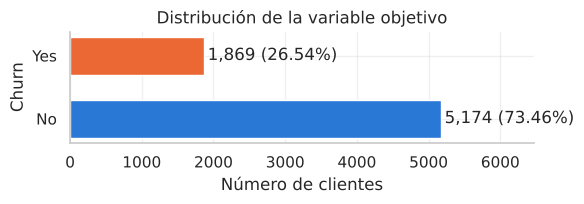

In [7]:
# Conteo y proporción de cada clase de la variable objetivo
dist_target = pd.DataFrame({
    "clientes": eda[TARGET].value_counts(),
    "porcentaje": (eda[TARGET].value_counts(normalize=True) * 100).round(2),
})
display(dist_target)

# Gráfica de barras horizontal con etiqueta directa del porcentaje
fig, ax = plt.subplots(figsize=(6, 2.2))
ax.barh(dist_target.index, dist_target["clientes"],
        color=[PALETA_CHURN[i] for i in dist_target.index], height=0.6)
for i, (n, p) in enumerate(zip(dist_target["clientes"], dist_target["porcentaje"])):
    ax.text(n + 50, i, f"{n:,} ({p}%)", va="center")
ax.set_xlabel("Número de clientes"); ax.set_ylabel("Churn")
ax.set_title("Distribución de la variable objetivo")
ax.set_xlim(0, dist_target["clientes"].max() * 1.25)
plt.tight_layout(); plt.show()

**Lectura:** el problema está **desbalanceado** (≈73% *No* vs ≈27% *Yes*). Esto tiene dos consecuencias para el resto del flujo:
1. La partición train/test debe ser **estratificada** para conservar esa proporción en ambos conjuntos.
2. La *accuracy* sola es engañosa: un modelo que siempre diga "No" ya obtiene ≈73%. Por eso se reportarán también *precision*, *recall*, F1 y ROC-AUC, y se comparará contra un clasificador trivial.

### 2.2 Distribución de las variables numéricas

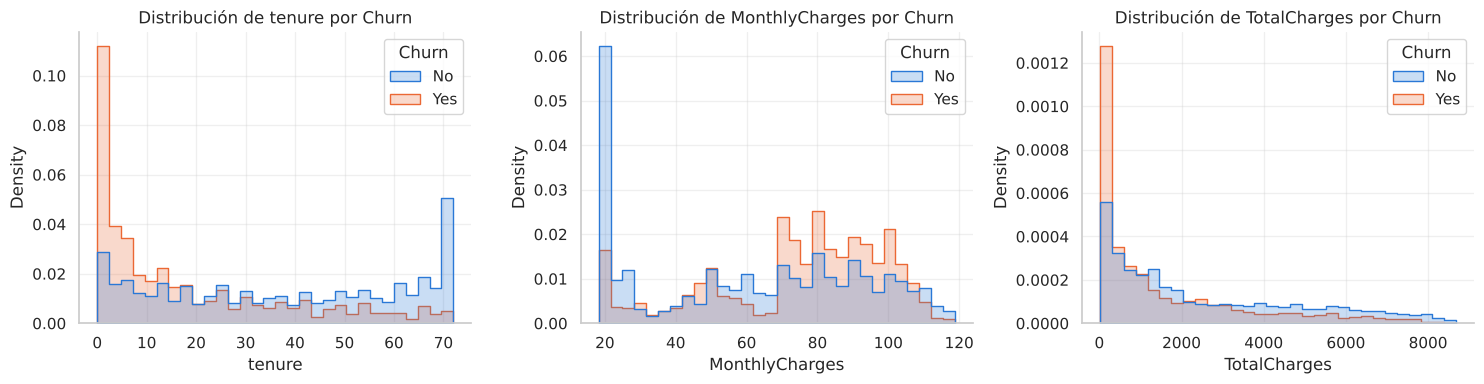

In [8]:
# Histogramas de cada variable numérica, separados por clase de Churn
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, NUM_COLS):
    sns.histplot(data=eda, x=col, hue=TARGET, bins=30, element="step",
                 stat="density", common_norm=False, palette=PALETA_CHURN, ax=ax)
    ax.set_title(f"Distribución de {col} por Churn")
plt.tight_layout(); plt.show()

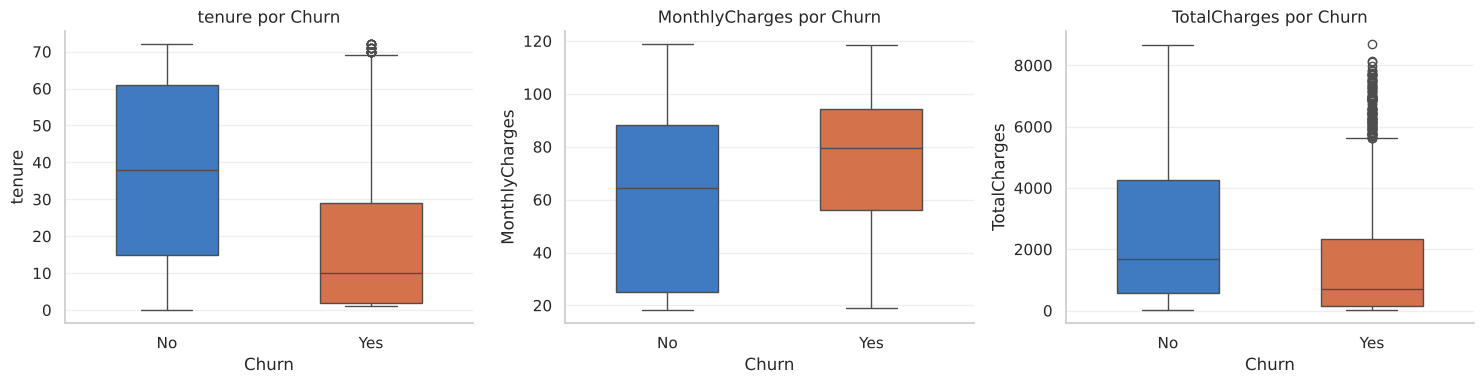

,tenure,MonthlyCharges,TotalCharges
Churn,,,
No,38.0,64.43,1683.60
Yes,10.0,79.65,703.55


In [9]:
# Boxplots: comparan mediana y dispersión de cada numérica entre quienes se van y quienes se quedan
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, NUM_COLS):
    sns.boxplot(data=eda, x=TARGET, y=col, hue=TARGET, palette=PALETA_CHURN,
                width=0.5, linewidth=1, legend=False, ax=ax)
    ax.set_title(f"{col} por Churn")
plt.tight_layout(); plt.show()

# Medianas por grupo para respaldar la lectura de las gráficas con números
eda.groupby(TARGET)[NUM_COLS].median().round(2)

**Lectura:**
- **`tenure`** es bimodal: muchos clientes nuevos (0–5 meses) y muchos muy antiguos (≈70 meses). Los clientes que abandonan se concentran fuertemente en los **primeros meses** (mediana ≈10 meses vs ≈38 de quienes se quedan).
- **`MonthlyCharges`** es mayor entre quienes abandonan (mediana ≈80 vs ≈65 USD): pagar más por mes se asocia a mayor riesgo.
- **`TotalCharges`** tiene fuerte sesgo a la derecha y es *menor* entre quienes se van, lo cual no contradice lo anterior: se van pronto y por eso acumulan menos.
- En los boxplots de `tenure` y `TotalCharges` del grupo *Yes* aparecen puntos más allá del bigote superior: son clientes **antiguos que también se fueron**. Son atípicos *dentro de ese grupo*, pero no respecto al total de clientes; en el Paso 3 se revisa con el criterio IQR sobre toda la variable.

### 2.3 Variables categóricas vs. tasa de *churn*

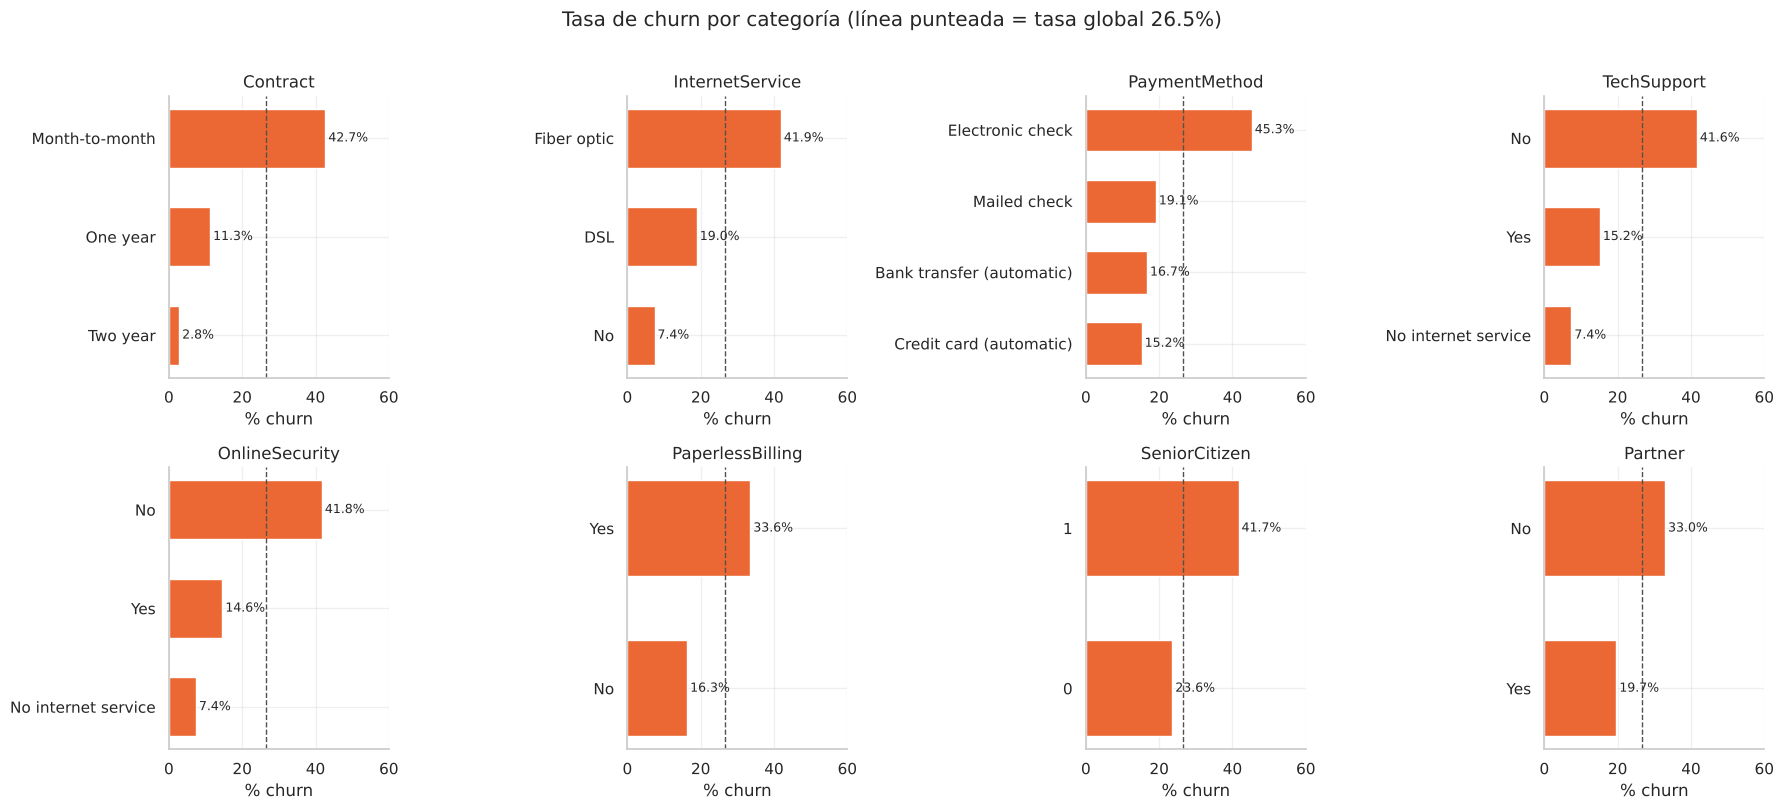

In [10]:
# Tasa de churn (% de clientes que abandonan) para cada categoría de las variables más relevantes
vars_clave = ["Contract", "InternetService", "PaymentMethod", "TechSupport",
              "OnlineSecurity", "PaperlessBilling", "SeniorCitizen", "Partner"]
tasa_global = (eda[TARGET] == "Yes").mean() * 100

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.ravel(), vars_clave):
    # Porcentaje de "Yes" por categoría, ordenado de mayor a menor
    tasa = (eda.groupby(col)[TARGET].apply(lambda s: (s == "Yes").mean() * 100)
              .sort_values(ascending=True))
    ax.barh(tasa.index.astype(str), tasa.values, color=COLOR_YES, height=0.6)
    ax.axvline(tasa_global, color="#52514e", ls="--", lw=1)   # referencia: tasa global
    for i, v in enumerate(tasa.values):
        ax.text(v + 0.8, i, f"{v:.1f}%", va="center", fontsize=9)
    ax.set_xlim(0, 60); ax.set_title(col); ax.set_xlabel("% churn")
fig.suptitle(f"Tasa de churn por categoría (línea punteada = tasa global {tasa_global:.1f}%)", y=1.01)
plt.tight_layout(); plt.show()

**Lectura (las relaciones más fuertes del dataset):**
- **Tipo de contrato** es el factor más claro: ≈43% de *churn* en contratos mes a mes contra ≈11% en contratos anuales y ≈3% en contratos de dos años.
- **Fibra óptica** tiene una tasa de abandono (≈42%) muy superior a DSL (≈19%), posiblemente por precio o por calidad percibida del servicio.
- **Pago con cheque electrónico** concentra ≈45% de abandono, el triple que los pagos automáticos.
- No contar con **soporte técnico** o **seguridad en línea** casi triplica el riesgo frente a quienes sí los tienen.
- Los **adultos mayores** y los clientes **sin pareja** abandonan más que el promedio.

### 2.4 Correlación entre variables numéricas

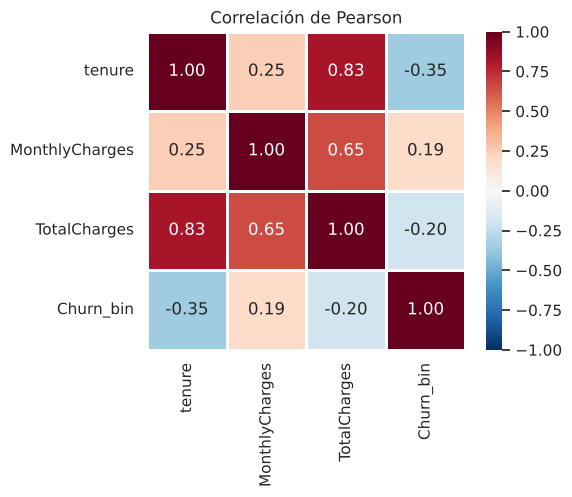

In [11]:
# Matriz de correlación de Pearson entre numéricas + objetivo codificado (1 = Yes)
corr = eda[NUM_COLS].assign(Churn_bin=(eda[TARGET] == "Yes").astype(int)).corr()

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, center=0,
            linewidths=2, linecolor="white", square=True, ax=ax)
ax.set_title("Correlación de Pearson")
plt.tight_layout(); plt.show()

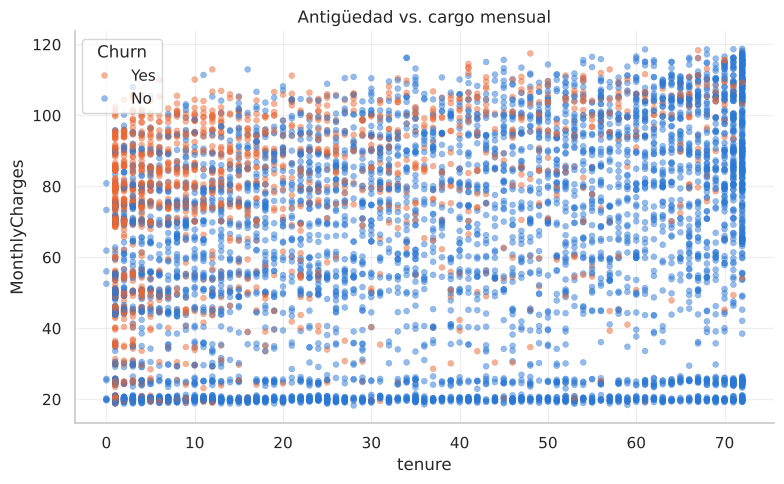

In [12]:
# Dispersión tenure vs MonthlyCharges coloreada por Churn: muestra la interacción entre ambas
fig, ax = plt.subplots(figsize=(8, 5))
sns.scatterplot(data=eda.sample(frac=1, random_state=RANDOM_STATE), x="tenure",
                y="MonthlyCharges", hue=TARGET, palette=PALETA_CHURN,
                alpha=0.5, s=18, edgecolor=None, ax=ax)
ax.set_title("Antigüedad vs. cargo mensual")
plt.tight_layout(); plt.show()

**Lectura:**
- `TotalCharges` está muy correlacionada con `tenure` (≈0.83) y moderadamente con `MonthlyCharges` (≈0.65): tiene sentido, porque el cargo acumulado es aproximadamente *antigüedad × cargo mensual*. Esta **multicolinealidad** hay que tenerla presente al interpretar los coeficientes del modelo lineal.
- `tenure` es la numérica con la correlación más fuerte con el *churn* (≈ −0.35).
- El diagrama de dispersión muestra la zona de mayor riesgo: **clientes nuevos con cargo mensual alto** (esquina superior izquierda).

## Paso 3. Limpieza de datos

Se revisan los cuatro problemas solicitados —tipos incorrectos, valores faltantes, duplicados y *outliers*— y se documenta **qué se encontró, qué se decidió y por qué**. Al final se registra una bitácora con todas las decisiones (que también se guarda en MLflow).

In [13]:
# Bitácora de limpieza: cada decisión se agrega aquí y luego se registra en MLflow
bitacora_limpieza = []
n_inicial = len(df)

### 3.1 Tipos incorrectos

In [14]:
# Se buscan los valores de TotalCharges que NO se pueden convertir a número
no_numericos = df.loc[pd.to_numeric(df["TotalCharges"], errors="coerce").isna(), "TotalCharges"]
print(f"Valores no numéricos en TotalCharges: {len(no_numericos)}")
print("Valores encontrados:", no_numericos.unique().tolist())

# Conversión: se quitan espacios y las cadenas vacías se convierten en NaN explícitos
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"].str.strip().replace("", np.nan))

# SeniorCitizen está como 0/1 pero es categórica: se recodifica a No/Yes como el resto
df["SeniorCitizen"] = df["SeniorCitizen"].map({0: "No", 1: "Yes"})

bitacora_limpieza.append(f"TotalCharges convertida de texto a float ({len(no_numericos)} cadenas vacías -> NaN).")
bitacora_limpieza.append("SeniorCitizen recodificada de 0/1 a No/Yes (variable categórica).")
df[["TotalCharges", "SeniorCitizen"]].dtypes

Valores no numéricos en TotalCharges: 11
Valores encontrados: [' ']


TotalCharges     float64
SeniorCitizen        str
dtype: object

**Decisión:** `TotalCharges` contenía **11 valores que eran solo un espacio en blanco** (`' '`), por eso pandas la leyó como texto. Se convierte a `float` y esos espacios pasan a ser `NaN` explícitos para tratarlos como faltantes. `SeniorCitizen` se recodifica a *No/Yes* para que el modelo la trate como categórica y no como una magnitud.

### 3.2 Valores faltantes

In [15]:
# Conteo de faltantes por columna (solo se muestran las columnas con al menos uno)
faltantes = df.isna().sum()
print("Columnas con faltantes:\n", faltantes[faltantes > 0])

# Se inspeccionan los registros con TotalCharges faltante para entender su origen
df.loc[df["TotalCharges"].isna(), ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Contract", TARGET]]

Columnas con faltantes:
 TotalCharges    11
dtype: int64


,customerID,tenure,MonthlyCharges,TotalCharges,Contract,Churn
488,4472-LVYGI,0,52.55,NaN,Two year,No
753,3115-CZMZD,0,20.25,NaN,Two year,No
936,5709-LVOEQ,0,80.85,NaN,Two year,No
1082,4367-NUYAO,0,25.75,NaN,Two year,No
1340,1371-DWPAZ,0,56.05,NaN,Two year,No
3331,7644-OMVMY,0,19.85,NaN,Two year,No
3826,3213-VVOLG,0,25.35,NaN,Two year,No
4380,2520-SGTTA,0,20.00,NaN,Two year,No
5218,2923-ARZLG,0,19.70,NaN,One year,No
6670,4075-WKNIU,0,73.35,NaN,Two year,No


In [16]:
# Imputación con 0: todos los faltantes corresponden a clientes con tenure = 0 (aún no se les factura)
assert (df.loc[df["TotalCharges"].isna(), "tenure"] == 0).all(), "Hay faltantes con tenure > 0"
n_imputados = df["TotalCharges"].isna().sum()
df["TotalCharges"] = df["TotalCharges"].fillna(0.0)

bitacora_limpieza.append(f"{n_imputados} faltantes de TotalCharges imputados con 0 (todos con tenure = 0).")
print(f"Faltantes restantes en todo el dataset: {df.isna().sum().sum()}")

Faltantes restantes en todo el dataset: 0


**Decisión:** los 11 faltantes son **todos clientes con `tenure = 0`**, es decir, se acaban de dar de alta y todavía no han recibido su primera factura. El faltante no es aleatorio: tiene una explicación de negocio. Por eso se imputa **`TotalCharges = 0`** (su cargo acumulado real), en lugar de usar la media o la mediana —que inventaría un historial que no existe— o eliminar las filas —que quitaría justamente a los clientes nuevos, el segmento de mayor riesgo—.

### 3.3 Duplicados

In [17]:
# 1) Duplicados exactos (todas las columnas, incluido el ID)
dup_exactos = df.duplicated().sum()
# 2) IDs de cliente repetidos
dup_ids = df["customerID"].duplicated().sum()
# 3) Perfiles idénticos ignorando el ID (clientes distintos con las mismas características)
dup_perfil = df.drop(columns="customerID").duplicated().sum()

print(f"Filas duplicadas exactas          : {dup_exactos}")
print(f"customerID repetidos              : {dup_ids}")
print(f"Perfiles idénticos (sin el ID)    : {dup_perfil}")

# Ejemplo de perfiles idénticos para entender qué tipo de cliente son
cols_sin_id = [c for c in df.columns if c != "customerID"]
display(df[df.duplicated(subset=cols_sin_id, keep=False)].sort_values(cols_sin_id).head(4))

bitacora_limpieza.append(f"Duplicados: {dup_exactos} exactos, {dup_ids} IDs repetidos; "
                         f"{dup_perfil} perfiles idénticos con ID distinto se conservan.")

Filas duplicadas exactas          : 0
customerID repetidos              : 0
Perfiles idénticos (sin el ID)    : 22


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
6491,9728-FTTVZ,Female,No,No,No,1,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,69.2,69.2,Yes
6764,7660-HDPJV,Female,No,No,No,1,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,69.2,69.2,Yes
4495,4702-IOQDC,Female,No,No,No,1,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.1,70.1,Yes
6267,0328-GRPMV,Female,No,No,No,1,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.1,70.1,Yes


**Decisión:** no hay filas duplicadas ni `customerID` repetidos, así que **no se elimina ningún registro**. Sí existen **22 perfiles idénticos con IDs distintos**: son clientes reales y diferentes con un perfil muy común (por ejemplo, clientes nuevos sin internet que pagan la tarifa mínima). Eliminarlos distorsionaría la frecuencia real de ese segmento, por lo que **se conservan**.

### 3.4 *Outliers*
Se usa el criterio del rango intercuartílico (IQR): un valor es atípico si está fuera de [Q1 − 1.5·IQR, Q3 + 1.5·IQR].

In [18]:
# Detección de outliers por IQR en cada variable numérica
filas = []
for col in NUM_COLS:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    lim_inf, lim_sup = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = ((df[col] < lim_inf) | (df[col] > lim_sup)).sum()
    filas.append({"variable": col, "min": df[col].min(), "max": df[col].max(),
                  "lim_inf_IQR": round(lim_inf, 2), "lim_sup_IQR": round(lim_sup, 2),
                  "outliers": n_out})
tabla_outliers = pd.DataFrame(filas)
display(tabla_outliers)

# Validación de reglas de negocio (valores imposibles)
print("tenure fuera de 0-72         :", (~df["tenure"].between(0, 72)).sum())
print("MonthlyCharges <= 0          :", (df["MonthlyCharges"] <= 0).sum())
print("TotalCharges < 0             :", (df["TotalCharges"] < 0).sum())

bitacora_limpieza.append("Outliers (IQR): 0 en tenure, MonthlyCharges y TotalCharges; sin valores imposibles. No se recorta nada.")

,variable,min,max,lim_inf_IQR,lim_sup_IQR,outliers
0,tenure,0.00,72.00,-60.00,124.00,0
1,MonthlyCharges,18.25,118.75,-46.02,171.38,0
2,TotalCharges,0.00,8684.80,-4683.52,8868.67,0


tenure fuera de 0-72         : 0
MonthlyCharges <= 0          : 0
TotalCharges < 0             : 0


**Decisión:** el criterio IQR **no detecta *outliers*** en ninguna variable numérica y no hay valores imposibles (antigüedad negativa, cargos ≤ 0). El sesgo de `TotalCharges` es real (clientes antiguos acumulan mucho), no un error, así que **no se recorta ni se transforma**. Como el modelo base es una regresión logística, las numéricas se **estandarizarán** dentro del *pipeline* para que la diferencia de escalas no afecte el entrenamiento.

### 3.5 Preparación final

In [19]:
# Se elimina el identificador (no tiene poder predictivo y provocaría sobreajuste)
df = df.drop(columns="customerID")
bitacora_limpieza.append("customerID eliminado (identificador sin valor predictivo).")

# Variable objetivo a binaria: 1 = abandona, 0 = se queda
df[TARGET] = (df[TARGET] == "Yes").astype(int)
bitacora_limpieza.append("Churn codificada como 1 = Yes, 0 = No.")

# Bitácora final
print(f"Registros: {n_inicial:,} -> {len(df):,} (no se eliminaron filas)\n")
for i, paso in enumerate(bitacora_limpieza, 1):
    print(f"{i}. {paso}")
df.info()

Registros: 7,043 -> 7,043 (no se eliminaron filas)

1. TotalCharges convertida de texto a float (11 cadenas vacías -> NaN).
2. SeniorCitizen recodificada de 0/1 a No/Yes (variable categórica).
3. 11 faltantes de TotalCharges imputados con 0 (todos con tenure = 0).
4. Duplicados: 0 exactos, 0 IDs repetidos; 22 perfiles idénticos con ID distinto se conservan.
5. Outliers (IQR): 0 en tenure, MonthlyCharges y TotalCharges; sin valores imposibles. No se recorta nada.
6. customerID eliminado (identificador sin valor predictivo).
7. Churn codificada como 1 = Yes, 0 = No.


<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            7043 non-null   str    
 1   SeniorCitizen     7043 non-null   str    
 2   Partner           7043 non-null   str    
 3   Dependents        7043 non-null   str    
 4   tenure            7043 non-null   int64  
 5   PhoneService      7043 non-null   str    
 6   MultipleLines     7043 non-null   str    
 7   InternetService   7043 non-null   str    
 8   OnlineSecurity    7043 non-null   str    
 9   OnlineBackup      7043 non-null   str    
 10  DeviceProtection  7043 non-null   str    
 11  TechSupport       7043 non-null   str    
 12  StreamingTV       7043 non-null   str    
 13  StreamingMovies   7043 non-null   str    
 14  Contract          7043 non-null   str    
 15  PaperlessBilling  7043 non-null   str    
 16  PaymentMethod     7043 non-null   str    
 17  Monthl

## Siguiente paso: `train.py`

Las decisiones de esta sección se implementan en la función `clean_data()` de `train.py`:

| Decisión | Implementación en `train.py` |
|---|---|
| `TotalCharges` de texto a número; 11 vacíos → 0 (clientes con `tenure = 0`) | `pd.to_numeric(...)` + `fillna(0.0)` |
| `SeniorCitizen` 0/1 → No/Yes | `map({0: "No", 1: "Yes"})` |
| Sin duplicados ni outliers por IQR | No se elimina ningún registro |
| `customerID` sin valor predictivo | `drop(columns="customerID")` |
| Escalado de numéricas y one-hot de categóricas | Dentro del `Pipeline`, ajustado solo con entrenamiento |

```bash
python train.py --help
```